In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("customer_churn_data.csv")

In [4]:
df.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,1,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,2,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,3,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,4,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,5,42,Male,32,69.01,Month-to-Month,NaN,2208.32,No,Yes


In [5]:
df.tail()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
995,996,42,Male,41,37.14,Month-to-Month,Fiber Optic,1522.74,Yes,Yes
996,997,62,Male,9,80.93,Month-to-Month,NaN,728.37,No,Yes
997,998,51,Female,15,111.72,Month-to-Month,Fiber Optic,1675.80,Yes,Yes
998,999,39,Male,68,65.67,One-Year,NaN,4465.56,No,Yes
999,1000,50,Male,1,56.67,Month-to-Month,NaN,56.67,No,Yes


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       1000 non-null   int64  
 1   Age              1000 non-null   int64  
 2   Gender           1000 non-null   object 
 3   Tenure           1000 non-null   int64  
 4   MonthlyCharges   1000 non-null   float64
 5   ContractType     1000 non-null   object 
 6   InternetService  703 non-null    object 
 7   TotalCharges     1000 non-null   float64
 8   TechSupport      1000 non-null   object 
 9   Churn            1000 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 78.3+ KB


In [7]:
df.isna().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
MonthlyCharges       0
ContractType         0
InternetService    297
TotalCharges         0
TechSupport          0
Churn                0
dtype: int64

In [8]:
df["InternetService"] = df["InternetService"].fillna("")

df.isna().sum().sum()

np.int64(0)

In [9]:
df.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,1,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,2,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,3,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,4,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,5,42,Male,32,69.01,Month-to-Month,,2208.32,No,Yes


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe()

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,500.500000,44.674000,18.97300,74.391290,1404.364060
std,288.819436,9.797741,18.89257,25.712083,1571.755048
min,1.000000,12.000000,0.00000,30.000000,0.000000
25%,250.750000,38.000000,5.00000,52.357500,345.217500
50%,500.500000,45.000000,13.00000,74.060000,872.870000
75%,750.250000,51.000000,26.00000,96.102500,1900.175000
max,1000.000000,83.000000,122.00000,119.960000,12416.250000


In [12]:
numeric_columns_data = df.select_dtypes (include = ("number"))

In [13]:
numeric_columns_data.corr()

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
CustomerID,1.000000,0.036730,-0.018585,-0.030504,-0.027490
Age,0.036730,1.000000,0.000472,0.006362,-0.001896
Tenure,-0.018585,0.000472,1.000000,-0.014552,0.894868
MonthlyCharges,-0.030504,0.006362,-0.014552,1.000000,0.304893
TotalCharges,-0.027490,-0.001896,0.894868,0.304893,1.000000


In [14]:
import matplotlib.pyplot as plt

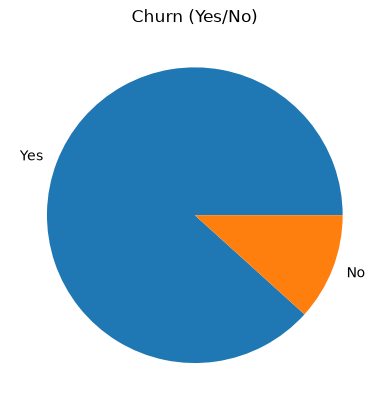

In [15]:
df["Churn"].value_counts().plot(kind="pie")
plt.title ("Churn (Yes/No)")
plt.ylabel("")
plt.show()

In [16]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     62.54641
Yes    75.96077
Name: MonthlyCharges, dtype: float64

In [17]:
df.groupby(["Churn","Gender"])["MonthlyCharges"].mean()

Churn  Gender
No     Female    65.091912
       Male      59.013878
Yes    Female    74.975064
       Male      77.082518
Name: MonthlyCharges, dtype: float64

In [18]:
df.groupby("Churn")["Tenure"].mean()

Churn
No     30.264957
Yes    17.476784
Name: Tenure, dtype: float64

In [19]:
df.groupby("Churn")["Age"].mean()

Churn
No     43.487179
Yes    44.831257
Name: Age, dtype: float64

At the lower terms we can see that the monthly charges average decreases

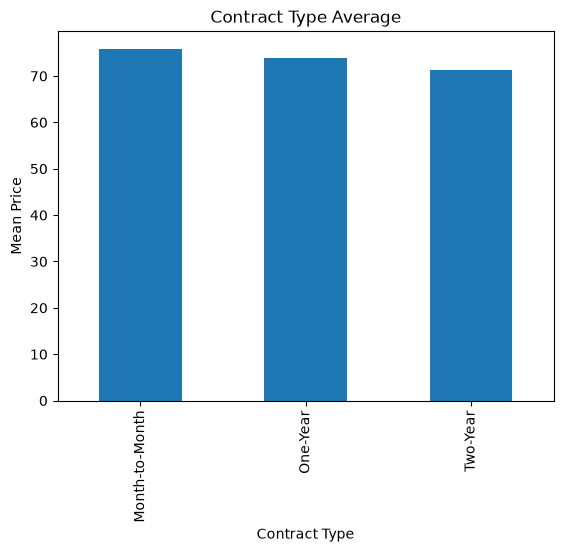

In [20]:
df.groupby("ContractType")["MonthlyCharges"].mean().plot(kind="bar")
plt.ylabel("Mean Price")
plt.xlabel("Contract Type")
plt.title("Contract Type Average")
plt.show()

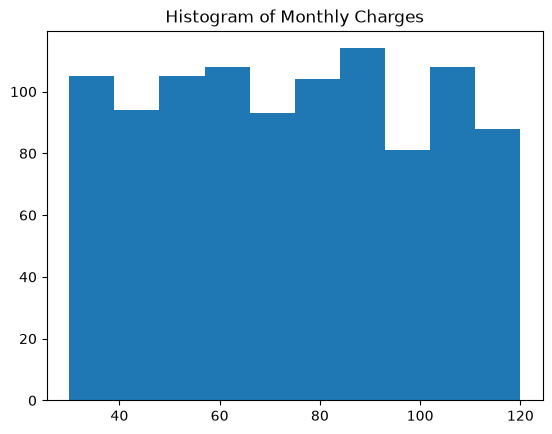

In [21]:
plt.hist(df["MonthlyCharges"])
plt.title("Histogram of Monthly Charges")
plt.show()

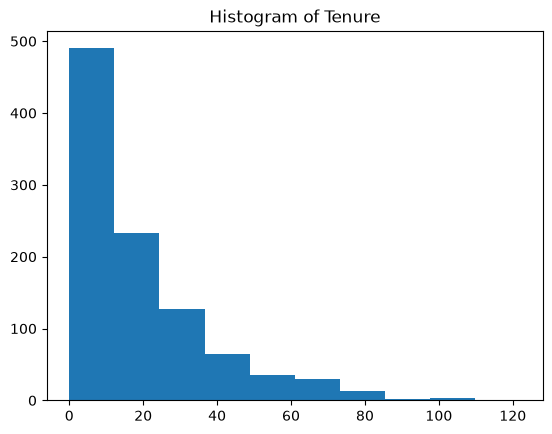

In [22]:
plt.hist(df["Tenure"])
plt.title("Histogram of Tenure")
plt.show()

In [23]:
y = df["Churn"]

x = df[["Age", "Gender", "Tenure", "MonthlyCharges"]]

In [24]:
y

0      Yes
1      Yes
2      Yes
3      Yes
4      Yes
      ... 
995    Yes
996    Yes
997    Yes
998    Yes
999    Yes
Name: Churn, Length: 1000, dtype: object

In [25]:
x #1 Female 0 Male

,Age,Gender,Tenure,MonthlyCharges
0,49,Male,4,88.35
1,43,Male,0,36.67
2,51,Female,2,63.79
3,60,Female,8,102.34
4,42,Male,32,69.01
...,...,...,...,...
995,42,Male,41,37.14
996,62,Male,9,80.93
997,51,Female,15,111.72
998,39,Male,68,65.67


In [26]:
x["Gender"] = x["Gender"].apply(lambda x:1 if x == "Female" else 0)

C:\Users\Sriram Avinesh\AppData\Local\Temp\ipykernel_18264\3459503666.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x["Gender"] = x["Gender"].apply(lambda x:1 if x == "Female" else 0)


In [27]:
y

0      Yes
1      Yes
2      Yes
3      Yes
4      Yes
      ... 
995    Yes
996    Yes
997    Yes
998    Yes
999    Yes
Name: Churn, Length: 1000, dtype: object

In [28]:
x.head()

,Age,Gender,Tenure,MonthlyCharges
0,49,0,4,88.35
1,43,0,0,36.67
2,51,1,2,63.79
3,60,1,8,102.34
4,42,0,32,69.01


In [29]:
type(x["Gender"][0])

numpy.int64

In [30]:
y = df["Churn"].apply(lambda x: 1 if x == "Yes" else 0)
y.value_counts()
                             

Churn
1    883
0    117
Name: count, dtype: int64

In [31]:
y = df["Churn"].apply(lambda x: 1 if x == "Yes" else 0)

In [32]:
type(y[0])

numpy.int64

In [33]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size = 0.2)

In [34]:
x


,Age,Gender,Tenure,MonthlyCharges
0,49,0,4,88.35
1,43,0,0,36.67
2,51,1,2,63.79
3,60,1,8,102.34
4,42,0,32,69.01
...,...,...,...,...
995,42,0,41,37.14
996,62,0,9,80.93
997,51,1,15,111.72
998,39,0,68,65.67


In [35]:
from sklearn.preprocessing import StandardScaler

In [36]:
scaler = StandardScaler()

In [37]:
X_train = scaler.fit_transform(x_train)

In [38]:
import joblib
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [39]:
x_test = scaler.fit_transform(x_train)

In [40]:
x_train

,Age,Gender,Tenure,MonthlyCharges
211,56,1,11,71.85
168,42,1,19,46.14
283,32,1,20,74.33
884,51,0,2,66.24
684,32,0,11,104.91
...,...,...,...,...
756,49,0,6,104.09
255,40,1,2,42.34
680,52,0,36,63.72
90,45,1,9,51.91


In [41]:
x_test

array([[ 1.17863836,  0.93933644, -0.42764198, -0.08998645],
       [-0.26280624,  0.93933644, -0.00364373, -1.08617112],
       [-1.29240952,  0.93933644,  0.04935605,  0.00610604],
       ...,
       [ 0.76679704, -1.06458129,  0.89735254, -0.40499934],
       [ 0.04607475,  0.93933644, -0.53364154, -0.86260109],
       [-1.29240952,  0.93933644,  1.10935166,  0.32693097]],
      shape=(800, 4))

In [42]:
from sklearn.metrics import accuracy_score

def modelperformance(predictions):
    print("Accuracy score on model is {}".format(accuracy_score(y_test, predictions)))

In [43]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [44]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 4)
(200, 4)
(800,)
(200,)


In [45]:
from sklearn.model_selection import GridSearchCV

In [46]:
from sklearn.linear_model import LogisticRegression

In [47]:
log_model = LogisticRegression()

In [48]:
import warnings
warnings.filterwarnings("ignore")

In [49]:
log_model.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [50]:
y_pred = log_model.predict(x_test)

In [51]:
modelperformance(y_pred)

Accuracy score on model is 0.885


In [52]:
print("X shape:", x.shape)
print("Y shape:", y.shape)

print("\nChurn distribution:")
print(y.value_counts())

print("\nGender distribution:")
print(x["Gender"].value_counts())

X shape: (1000, 4)
Y shape: (1000,)

Churn distribution:
Churn
1    883
0    117
Name: count, dtype: int64

Gender distribution:
Gender
1    538
0    462
Name: count, dtype: int64


In [53]:
print("Actual values:")
print(y_test.value_counts())

print("\nPredicted values:")
print(pd.Series(y_pred).value_counts())

Actual values:
Churn
1    177
0     23
Name: count, dtype: int64

Predicted values:
1    198
0      2
Name: count, dtype: int64


In [54]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)


[[  1  22]
 [  1 176]]


In [55]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.50      0.04      0.08        23
           1       0.89      0.99      0.94       177

    accuracy                           0.89       200
   macro avg       0.69      0.52      0.51       200
weighted avg       0.84      0.89      0.84       200



In [56]:
print("Model coefficients:")
print(log_model.coef_)

print("\nModel intercept:")
print(log_model.intercept_)

Model coefficients:
[[ 0.0176358  -0.27780438 -0.0306688   0.02085865]]

Model intercept:
[0.65869632]


In [57]:
import numpy as np
import pandas as pd

odds_ratios = np.exp(log_model.coef_[0])

feature_importance = pd.DataFrame({
    "Feature": x.columns,
    "Coefficient": log_model.coef_[0],
    "Odds Ratio": odds_ratios
})

feature_importance

,Feature,Coefficient,Odds Ratio
0,Age,0.017636,1.017792
1,Gender,-0.277804,0.757445
2,Tenure,-0.030669,0.969797
3,MonthlyCharges,0.020859,1.021078


In [58]:
x.describe()

,Age,Gender,Tenure,MonthlyCharges
count,1000.000000,1000.000000,1000.00000,1000.000000
mean,44.674000,0.538000,18.97300,74.391290
std,9.797741,0.498803,18.89257,25.712083
min,12.000000,0.000000,0.00000,30.000000
25%,38.000000,0.000000,5.00000,52.357500
50%,45.000000,1.000000,13.00000,74.060000
75%,51.000000,1.000000,26.00000,96.102500
max,83.000000,1.000000,122.00000,119.960000


In [59]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

numerical_features = ["Age", "Tenure", "MonthlyCharges"]

x_train_scaled[numerical_features] = scaler.fit_transform(
    x_train[numerical_features]
)

x_test_scaled[numerical_features] = scaler.transform(
    x_test[numerical_features]
)

In [60]:
x_train_scaled.describe()

,Age,Gender,Tenure,MonthlyCharges
count,8.000000e+02,800.000000,8.000000e+02,8.000000e+02
mean,-3.419487e-16,0.532500,2.664535e-17,3.730349e-16
std,1.000626e+00,0.499255,1.000626e+00,1.000626e+00
min,-3.339463e+00,0.000000,-9.974118e-01,-1.757359e+00
25%,-6.873753e-01,0.000000,-7.330392e-01,-8.595712e-01
50%,2.664838e-02,1.000000,-3.364803e-01,2.476039e-02
75%,6.386687e-01,1.000000,3.905445e-01,8.385473e-01
max,3.086750e+00,1.000000,5.453280e+00,1.802922e+00


In [61]:
from sklearn.linear_model import LogisticRegression

log_model_scaled = LogisticRegression()

log_model_scaled.fit(x_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [62]:
y_pred_scaled = log_model_scaled.predict(x_test_scaled)

In [63]:
modelperformance(y_pred_scaled)

Accuracy score on model is 0.885


In [64]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_scaled))

              precision    recall  f1-score   support

           0       0.50      0.04      0.08        23
           1       0.89      0.99      0.94       177

    accuracy                           0.89       200
   macro avg       0.69      0.52      0.51       200
weighted avg       0.84      0.89      0.84       200



In [65]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred_scaled))

[[  1  22]
 [  1 176]]


In [66]:
log_model_balanced = LogisticRegression(class_weight="balanced")

log_model_balanced.fit(x_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the fol

In [67]:
y_pred_balanced = log_model_balanced.predict(x_test_scaled)

In [68]:
print(pd.Series(y_pred_balanced).value_counts())

1    131
0     69
Name: count, dtype: int64


In [69]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       0.23      0.70      0.35        23
           1       0.95      0.70      0.81       177

    accuracy                           0.70       200
   macro avg       0.59      0.70      0.58       200
weighted avg       0.86      0.70      0.75       200



In [70]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred_balanced))

[[ 16   7]
 [ 53 124]]


In [71]:
y_prob = log_model_balanced.predict_proba(x_test_scaled)[:, 1]

In [72]:
print(y_prob[:10])

[0.84454937 0.8826866  0.81322054 0.64978117 0.59804777 0.65183563
 0.49190411 0.30696608 0.40007289 0.10887942]


In [73]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.7472365512159174


In [74]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_04 = (y_prob >= 0.4).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_04))

print(classification_report(y_test, y_pred_04))

Accuracy: 0.78
              precision    recall  f1-score   support

           0       0.23      0.39      0.29        23
           1       0.91      0.83      0.87       177

    accuracy                           0.78       200
   macro avg       0.57      0.61      0.58       200
weighted avg       0.83      0.78      0.80       200



In [75]:
y_pred_03 = (y_prob >= 0.3).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_03))

print(classification_report(y_test, y_pred_03))

Accuracy: 0.82
              precision    recall  f1-score   support

           0       0.19      0.17      0.18        23
           1       0.89      0.90      0.90       177

    accuracy                           0.82       200
   macro avg       0.54      0.54      0.54       200
weighted avg       0.81      0.82      0.82       200



In [76]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

pr_data = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision[:-1],
    "Recall": recall[:-1]
})

pr_data.head(10)


,Threshold,Precision,Recall
0,0.042817,0.885000,1.000000
1,0.047242,0.889447,1.000000
2,0.067026,0.888889,0.994350
3,0.074941,0.888325,0.988701
4,0.108879,0.887755,0.983051
5,0.110118,0.887179,0.977401
6,0.132334,0.886598,0.971751
7,0.135320,0.891192,0.971751
8,0.141597,0.890625,0.966102
9,0.159667,0.890052,0.960452


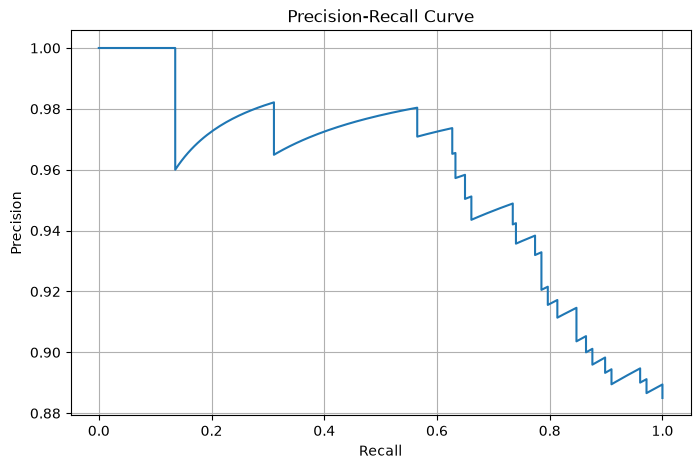

In [77]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")

plt.grid(True)
plt.show()


In [78]:
from sklearn.metrics import average_precision_score

ap_score = average_precision_score(y_test, y_prob)

print("Average Precision Score:", ap_score)

Average Precision Score: 0.9573163406285251


In [79]:
print("Positive class proportion:")
print(y_test.mean())

print("\nNegative class proportion:")
print(1 - y_test.mean())

print("\nAverage Precision:")
print(average_precision_score(y_test, y_prob))

Positive class proportion:
0.885

Negative class proportion:
0.11499999999999999

Average Precision:
0.9573163406285251


In [80]:
from sklearn.model_selection import train_test_split

# First split: 80% development, 20% testing
X_dev, X_test, y_dev, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=123,
    stratify=y
)

# Second split: 60% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    random_state=123,
    stratify=y_dev
)

In [81]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (600, 4) (600,)
Validation: (200, 4) (200,)
Testing: (200, 4) (200,)


In [82]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numerical_features = ["Age", "Tenure", "MonthlyCharges"]

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

X_val_scaled[numerical_features] = scaler.transform(
    X_val[numerical_features]
)

X_test_scaled[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

In [83]:
X_train_scaled.describe()

,Age,Gender,Tenure,MonthlyCharges
count,6.000000e+02,600.000000,6.000000e+02,6.000000e+02
mean,2.131628e-16,0.540000,5.921189e-17,-2.486900e-16
std,1.000834e+00,0.498813,1.000834e+00,1.000834e+00
min,-3.303298e+00,0.000000,-9.964241e-01,-1.774290e+00
25%,-6.797643e-01,0.000000,-7.384168e-01,-8.781921e-01
50%,2.657169e-02,1.000000,-3.256052e-01,6.636966e-02
75%,6.320026e-01,1.000000,3.968152e-01,8.573668e-01
max,3.860967e+00,1.000000,4.421729e+00,1.685866e+00


In [84]:
from sklearn.linear_model import LogisticRegression

log_model_final = LogisticRegression(class_weight="balanced")

log_model_final.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the fol

In [85]:
y_val_prob = log_model_final.predict_proba(X_val_scaled)[:, 1]

In [86]:
print(y_val_prob[:10])

[0.59375757 0.67422567 0.33257247 0.43517031 0.87777014 0.63366805
 0.2452967  0.45240581 0.23185523 0.70968108]


In [87]:
print(y_val_prob.shape)

(200,)


In [88]:
from sklearn.metrics import precision_recall_curve
import pandas as pd

precision, recall, thresholds = precision_recall_curve(
    y_val, y_val_prob
)

val_results = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision[:-1],
    "Recall": recall[:-1]
})

val_results.head(10)

,Threshold,Precision,Recall
0,0.041407,0.880000,1.000000
1,0.051483,0.879397,0.994318
2,0.097622,0.883838,0.994318
3,0.118133,0.888325,0.994318
4,0.128238,0.892857,0.994318
5,0.136441,0.892308,0.988636
6,0.147868,0.896907,0.988636
7,0.165893,0.896373,0.982955
8,0.177508,0.895833,0.977273
9,0.193048,0.895288,0.971591


In [89]:
from sklearn.metrics import f1_score
import numpy as np

threshold_results = []

for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    macro_f1 = f1_score(
        y_val, y_val_pred, average="macro"
    )

    threshold_results.append({
        "Threshold": threshold,
        "Macro_F1": macro_f1
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.sort_values(
    by="Macro_F1", ascending=False
).head(10)

,Threshold,Macro_F1
33,0.336856,0.641962
41,0.373539,0.641791
42,0.379101,0.637089
34,0.342396,0.637024
26,0.285243,0.634286
43,0.380946,0.632468
35,0.344197,0.632188
47,0.406118,0.631834
31,0.330823,0.631094
27,0.302828,0.629193


In [90]:
best_threshold = 0.336856

y_val_pred = (y_val_prob >= best_threshold).astype(int)

from sklearn.metrics import classification_report

print(classification_report(y_val, y_val_pred))

              precision    recall  f1-score   support

           0       0.33      0.46      0.39        24
           1       0.92      0.88      0.90       176

    accuracy                           0.82       200
   macro avg       0.63      0.67      0.64       200
weighted avg       0.85      0.82      0.84       200



In [91]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_val, y_val_pred))

[[ 11  13]
 [ 22 154]]


In [92]:
best_threshold = threshold_df.sort_values(
    by="Macro_F1", ascending=False
).iloc[0]["Threshold"]

print("Selected threshold:", best_threshold)

Selected threshold: 0.33685609423146967


In [93]:
y_test_prob = log_model_final.predict_proba(X_test_scaled)[:, 1]

y_test_pred = (y_test_prob >= best_threshold).astype(int)

In [94]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, average_precision_score

print("Accuracy:", accuracy_score(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nROC-AUC:", roc_auc_score(y_test, y_test_prob))

print("\nAverage Precision:", average_precision_score(y_test, y_test_prob))

Accuracy: 0.785

Classification Report:
              precision    recall  f1-score   support

           0       0.17      0.22      0.19        23
           1       0.89      0.86      0.88       177

    accuracy                           0.79       200
   macro avg       0.53      0.54      0.53       200
weighted avg       0.81      0.79      0.80       200


Confusion Matrix:
[[  5  18]
 [ 25 152]]

ROC-AUC: 0.6710881847211987

Average Precision: 0.9451284258410488


In [95]:
baseline_results = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "Threshold": [best_threshold],
    "Accuracy": [accuracy_score(y_test, y_test_pred)],
    "ROC-AUC": [roc_auc_score(y_test, y_test_prob)],
    "Average Precision": [
        average_precision_score(y_test, y_test_prob)
    ]
})

baseline_results

,Model,Threshold,Accuracy,ROC-AUC,Average Precision
0,Logistic Regression,0.336856,0.785,0.671088,0.945128


In [96]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [97]:
y_val_prob_rf = rf_model.predict_proba(X_val_scaled)[:, 1]

print("Validation probabilities generated!")
print("Shape:", y_val_prob_rf.shape)
print("First 10 probabilities:")
print(y_val_prob_rf[:10])

Validation probabilities generated!
Shape: (200,)
First 10 probabilities:
[0.9918631  0.99371429 0.17881033 0.25553056 0.99569643 0.99141916
 0.1744987  0.36412717 0.48071261 0.28781521]


In [98]:
from sklearn.metrics import f1_score
from sklearn.metrics import precision_recall_curve
import pandas as pd

precision_rf, recall_rf, thresholds_rf = precision_recall_curve(
    y_val, y_val_prob_rf
)

threshold_results_rf = []

for threshold in thresholds_rf:
    y_val_pred_rf = (y_val_prob_rf >= threshold).astype(int)

    macro_f1 = f1_score(
        y_val,
        y_val_pred_rf,
        average="macro"
    )

    threshold_results_rf.append({
        "Threshold": threshold,
        "Macro_F1": macro_f1
    })

threshold_df_rf = pd.DataFrame(threshold_results_rf)

threshold_df_rf.sort_values(
    by="Macro_F1",
    ascending=False
).head(10)

,Threshold,Macro_F1
63,0.431026,0.640116
64,0.432795,0.635781
65,0.435960,0.631490
62,0.426278,0.629684
66,0.436754,0.627240
67,0.444545,0.623031
57,0.394564,0.620728
61,0.401137,0.619048
68,0.447605,0.618859
78,0.480713,0.618371


In [99]:
from sklearn.metrics import classification_report, confusion_matrix

best_threshold_rf = threshold_df_rf.sort_values(
    by="Macro_F1",
    ascending=False
).iloc[0]["Threshold"]

y_val_pred_rf = (
    y_val_prob_rf >= best_threshold_rf
).astype(int)

print("Best Threshold:", best_threshold_rf)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

Best Threshold: 0.43102637624947326

Classification Report:
              precision    recall  f1-score   support

           0       0.30      0.79      0.44        24
           1       0.96      0.75      0.84       176

    accuracy                           0.76       200
   macro avg       0.63      0.77      0.64       200
weighted avg       0.88      0.76      0.79       200


Confusion Matrix:
[[ 19   5]
 [ 44 132]]


In [100]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [101]:
from xgboost import XGBClassifier

# Calculate class imbalance ratio
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("Scale Pos Weight:", scale_pos_weight)

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train_scaled, y_train)

print("XGBoost model trained successfully!")

Scale Pos Weight: 0.1320754716981132
XGBoost model trained successfully!


In [102]:
print("Training class distribution:")
print(y_train.value_counts().sort_index())

print("\nClass 0:", (y_train == 0).sum())
print("Class 1:", (y_train == 1).sum())
print(
    "Correct scale_pos_weight:",
    (y_train == 0).sum() / (y_train == 1).sum()
)

Training class distribution:
Churn
0     70
1    530
Name: count, dtype: int64

Class 0: 70
Class 1: 530
Correct scale_pos_weight: 0.1320754716981132


In [103]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=1,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_scaled, y_train)

print("XGBoost model retrained successfully!")

XGBoost model retrained successfully!


In [104]:
y_val_prob_xgb = xgb_model.predict_proba(X_val_scaled)[:, 1]

print("Validation probabilities generated!")
print("Shape:", y_val_prob_xgb.shape)
print("First 10 probabilities:")
print(y_val_prob_xgb[:10])

Validation probabilities generated!
Shape: (200,)
First 10 probabilities:
[0.99227977 0.9917105  0.49654692 0.6661204  0.99879164 0.9865832
 0.5270182  0.7335491  0.88708943 0.69036853]


In [105]:
from sklearn.metrics import f1_score
import pandas as pd

precision_xgb, recall_xgb, thresholds_xgb = precision_recall_curve(
    y_val, y_val_prob_xgb
)

threshold_results_xgb = []

for threshold in thresholds_xgb:
    y_val_pred_xgb = (y_val_prob_xgb >= threshold).astype(int)

    macro_f1 = f1_score(
        y_val,
        y_val_pred_xgb,
        average="macro"
    )

    threshold_results_xgb.append({
        "Threshold": threshold,
        "Macro_F1": macro_f1
    })

threshold_df_xgb = pd.DataFrame(threshold_results_xgb)

threshold_df_xgb.sort_values(
    by="Macro_F1",
    ascending=False
).head(10)

,Threshold,Macro_F1
70,0.827133,0.638437
53,0.778017,0.638133
57,0.782568,0.636209
64,0.804758,0.635781
71,0.833396,0.634167
54,0.778219,0.633700
58,0.789768,0.631845
65,0.808888,0.631490
51,0.771506,0.630769
72,0.835317,0.629934


In [106]:
from sklearn.metrics import classification_report, confusion_matrix

best_threshold_xgb = threshold_df_xgb.sort_values(
    by="Macro_F1",
    ascending=False
).iloc[0]["Threshold"]

y_val_pred_xgb = (
    y_val_prob_xgb >= best_threshold_xgb
).astype(int)

print("Best Threshold:", best_threshold_xgb)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_xgb))

Best Threshold: 0.8271332383155823

Classification Report:
              precision    recall  f1-score   support

           0       0.30      0.88      0.45        24
           1       0.98      0.72      0.83       176

    accuracy                           0.74       200
   macro avg       0.64      0.80      0.64       200
weighted avg       0.90      0.74      0.78       200


Confusion Matrix:
[[ 21   3]
 [ 49 127]]


In [107]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    f1_score
)

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Threshold": [
        best_threshold,
        best_threshold_rf,
        best_threshold_xgb
    ],
    "Accuracy": [
        accuracy_score(y_val, y_val_pred),
        accuracy_score(y_val, y_val_pred_rf),
        accuracy_score(y_val, y_val_pred_xgb)
    ],
    "Macro F1": [
        f1_score(y_val, y_val_pred, average="macro"),
        f1_score(y_val, y_val_pred_rf, average="macro"),
        f1_score(y_val, y_val_pred_xgb, average="macro")
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, y_val_prob),
        roc_auc_score(y_val, y_val_prob_rf),
        roc_auc_score(y_val, y_val_prob_xgb)
    ],
    "Average Precision": [
        average_precision_score(y_val, y_val_prob),
        average_precision_score(y_val, y_val_prob_rf),
        average_precision_score(y_val, y_val_prob_xgb)
    ]
})

model_comparison.round(4)

,Model,Threshold,Accuracy,Macro F1,ROC-AUC,Average Precision
0,Logistic Regression,0.3369,0.825,0.6420,0.7827,0.9647
1,Random Forest,0.4310,0.755,0.6401,0.8125,0.9733
2,XGBoost,0.8271,0.740,0.6384,0.8210,0.9746


In [108]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

models = {
    "Logistic Regression": (
        log_model_final,
        best_threshold
    ),
    "Random Forest": (
        rf_model,
        best_threshold_rf
    ),
    "XGBoost": (
        xgb_model,
        best_threshold_xgb
    )
}

final_results = []

for name, (model, threshold) in models.items():

    probabilities = model.predict_proba(X_test_scaled)[:, 1]

    predictions = (probabilities >= threshold).astype(int)

    final_results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "Macro F1": f1_score(y_test, predictions, average="macro"),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Average Precision": average_precision_score(y_test, probabilities)
    })

final_comparison = pd.DataFrame(final_results)

final_comparison.round(4)

,Model,Threshold,Accuracy,Precision,Recall,Macro F1,ROC-AUC,Average Precision
0,Logistic Regression,0.3369,0.785,0.8941,0.8588,0.5324,0.6711,0.9451
1,Random Forest,0.4310,0.765,0.9643,0.7627,0.6427,0.8421,0.9792
2,XGBoost,0.8271,0.745,0.9565,0.7458,0.6190,0.8206,0.9760


In [109]:
from sklearn.metrics import confusion_matrix, classification_report

rf_test_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

rf_test_pred = (
    rf_test_prob >= best_threshold_rf
).astype(int)

print("Random Forest Test Confusion Matrix:")
print(confusion_matrix(y_test, rf_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_test_pred))

Random Forest Test Confusion Matrix:
[[ 18   5]
 [ 42 135]]

Classification Report:
              precision    recall  f1-score   support

           0       0.30      0.78      0.43        23
           1       0.96      0.76      0.85       177

    accuracy                           0.77       200
   macro avg       0.63      0.77      0.64       200
weighted avg       0.89      0.77      0.80       200



In [110]:
import joblib

# Save Random Forest model
joblib.dump(rf_model, "churn_model.pkl")

# Save scaler
joblib.dump(scaler, "scaler.pkl")

# Save selected threshold
joblib.dump(best_threshold_rf, "threshold.pkl")

print("Model saved successfully!")
print("Scaler saved successfully!")
print("Threshold saved successfully!")

Model saved successfully!
Scaler saved successfully!
Threshold saved successfully!


http://localhost:8501/

In [113]:

# REVENUE AT RISK & CUSTOMER VALUE ANALYSIS

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load existing customer dataset
df = pd.read_csv("customer_churn_data.csv")

# Display dataset information
print("Dataset loaded successfully!")
print("Total customers:", len(df))
print("Total columns:", len(df.columns))

display(df.head())


Dataset loaded successfully!
Total customers: 1000
Total columns: 10


,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,1,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,2,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,3,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,4,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,5,42,Male,32,69.01,Month-to-Month,NaN,2208.32,No,Yes


In [114]:

# STEP 2: REVENUE EXPOSURE ANALYSIS

# Separate churned and active customers
churned_customers = df[df["Churn"] == "Yes"]
active_customers = df[df["Churn"] == "No"]

# Calculate customer counts
total_customers = len(df)
churned_count = len(churned_customers)
active_count = len(active_customers)

# Calculate monthly revenue exposure
churned_revenue = churned_customers["MonthlyCharges"].sum()
active_revenue = active_customers["MonthlyCharges"].sum()
total_revenue = df["MonthlyCharges"].sum()

# Calculate revenue percentages
churned_revenue_pct = (churned_revenue / total_revenue) * 100
active_revenue_pct = (active_revenue / total_revenue) * 100

# Display results
print("=" * 50)
print("REVENUE AT RISK ANALYSIS")
print("=" * 50)

print(f"\nTotal Customers: {total_customers}")
print(f"Churned Customers: {churned_count}")
print(f"Active Customers: {active_count}")

print("\nMONTHLY REVENUE ANALYSIS")

print(f"Revenue Associated with Churned Customers: ${churned_revenue:,.2f}")
print(f"Revenue Associated with Active Customers: ${active_revenue:,.2f}")
print(f"Total Monthly Revenue: ${total_revenue:,.2f}")

print("\nREVENUE DISTRIBUTION")

print(f"Churned Revenue Exposure: {churned_revenue_pct:.2f}%")
print(f"Active Revenue Contribution: {active_revenue_pct:.2f}%")


REVENUE AT RISK ANALYSIS

Total Customers: 1000
Churned Customers: 883
Active Customers: 117

MONTHLY REVENUE ANALYSIS
Revenue Associated with Churned Customers: $67,073.36
Revenue Associated with Active Customers: $7,317.93
Total Monthly Revenue: $74,391.29

REVENUE DISTRIBUTION
Churned Revenue Exposure: 90.16%
Active Revenue Contribution: 9.84%


Measuring the monthly charges associated with customers labelled as churned. This is a revenue exposure measure based on the dataset, not necessarily actual future revenue lost.

Business interpretation

The dataset indicates that customers labelled as churned account for $67,073.36 in monthly charges.
This is a substantial revenue exposure in the dataset.
However, because these customers have already churned, we should describe this as associated historical monthly revenue, not revenue that can still be recovered.

Our next objective: Identify which customer groups contribute most to this revenue exposure.

In [115]:

# STEP 3: REVENUE EXPOSURE BY CONTRACT TYPE

contract_analysis = df.groupby("ContractType").agg(
    Total_Customers=("CustomerID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum()),
    Monthly_Revenue=("MonthlyCharges", "sum")
)

# Calculate churn percentage
contract_analysis["Churn_Rate"] = (
    contract_analysis["Churned_Customers"] /
    contract_analysis["Total_Customers"] * 100
)

# Calculate churned customer revenue
churned_contract_revenue = (
    df[df["Churn"] == "Yes"]
    .groupby("ContractType")["MonthlyCharges"]
    .sum()
)

contract_analysis["Revenue_At_Risk"] = churned_contract_revenue

# Calculate percentage of total revenue exposure
contract_analysis["Revenue_Exposure_Pct"] = (
    contract_analysis["Revenue_At_Risk"] /
    churned_revenue * 100
)

# Display results
print("=" * 60)
print("REVENUE EXPOSURE BY CONTRACT TYPE")
print("=" * 60)

display(contract_analysis.round(2))


REVENUE EXPOSURE BY CONTRACT TYPE


,Total_Customers,Churned_Customers,Monthly_Revenue,Churn_Rate,Revenue_At_Risk,Revenue_Exposure_Pct
ContractType,,,,,,
Month-to-Month,511,511,38789.60,100.00,38789.60,57.83
One-Year,289,218,21334.79,75.43,16924.72,25.23
Two-Year,200,154,14266.90,77.00,11359.04,16.94


Three observations:
1. Month-to-Month contracts contribute the largest share of revenue exposure.
2. One-Year and Two-Year contracts also show substantial churn rates.
3. Contract type alone is not sufficient to explain customer behaviour. We need to investigate customer value and other characteristics.

Potential business recommendation: Investigate whether flexible-contract customers would respond to incentives for longer-term subscriptions. This is a hypothesis to test, not a proven retention solution.

In [116]:

# STEP 4: HIGH-VALUE CUSTOMER ANALYSIS

# Calculate average monthly charges
average_monthly_charge = df["MonthlyCharges"].mean()

# Classify customers by value
df["CustomerValue"] = np.where(
    df["MonthlyCharges"] >= average_monthly_charge,
    "High Value",
    "Standard Value"
)

# Analyse customer value and churn
value_analysis = df.groupby("CustomerValue").agg(
    Total_Customers=("CustomerID", "count"),
    Churned_Customers=(
        "Churn", lambda x: (x == "Yes").sum()
    ),
    Average_Monthly_Charges=("MonthlyCharges", "mean"),
    Total_Monthly_Revenue=("MonthlyCharges", "sum")
)

# Calculate churn rate
value_analysis["Churn_Rate"] = (
    value_analysis["Churned_Customers"] /
    value_analysis["Total_Customers"] * 100
)

# Calculate revenue associated with churned customers
value_analysis["Revenue_At_Risk"] = (
    df[df["Churn"] == "Yes"]
    .groupby("CustomerValue")["MonthlyCharges"]
    .sum()
)

print("=" * 60)
print("HIGH-VALUE CUSTOMER ANALYSIS")
print("=" * 60)

print(f"\nAverage Monthly Charge: ${average_monthly_charge:.2f}")

display(value_analysis.round(2))


HIGH-VALUE CUSTOMER ANALYSIS

Average Monthly Charge: $74.39


,Total_Customers,Churned_Customers,Average_Monthly_Charges,Total_Monthly_Revenue,Churn_Rate,Revenue_At_Risk
CustomerValue,,,,,,
High Value,496,462,96.90,48063.38,93.15,45097.65
Standard Value,504,421,52.24,26327.91,83.53,21975.71


Three important observations:
1. High-value customers have a higher observed churn rate.
2. They contribute approximately 67.25% of churn-associated monthly charges.
3. Their average monthly charges are nearly twice those of standard-value customers.

Business recommendation: High-value customers should be an important segment for retention investigation. Management should examine whether targeted service improvements or retention offers could help retain them.

Note: High value here means above-average monthly charges, not necessarily higher profitability.

In [117]:

# STEP 5: CUSTOMER VALUE AND CHURN MATRIX

# Create customer segments
df["CustomerSegment"] = np.where(
    df["CustomerValue"] == "High Value",
    np.where(
        df["Churn"] == "Yes",
        "High Value - Churned",
        "High Value - Active"
    ),
    np.where(
        df["Churn"] == "Yes",
        "Standard Value - Churned",
        "Standard Value - Active"
    )
)

# Analyse each segment
segment_analysis = df.groupby("CustomerSegment").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Monthly_Charges=("MonthlyCharges", "mean"),
    Total_Monthly_Charges=("MonthlyCharges", "sum")
)

# Calculate percentage of total customers
segment_analysis["Customer_Percentage"] = (
    segment_analysis["Customer_Count"] /
    len(df) * 100
)

# Calculate revenue share
segment_analysis["Revenue_Percentage"] = (
    segment_analysis["Total_Monthly_Charges"] /
    total_revenue * 100
)

print("=" * 65)
print("CUSTOMER VALUE AND CHURN SEGMENTATION")
print("=" * 65)

display(segment_analysis.round(2))


CUSTOMER VALUE AND CHURN SEGMENTATION


,Customer_Count,Average_Monthly_Charges,Total_Monthly_Charges,Customer_Percentage,Revenue_Percentage
CustomerSegment,,,,,
High Value - Active,34,87.23,2965.73,3.4,3.99
High Value - Churned,462,97.61,45097.65,46.2,60.62
Standard Value - Active,83,52.44,4352.20,8.3,5.85
Standard Value - Churned,421,52.20,21975.71,42.1,29.54


In [118]:

# STEP 6: REVENUE CONCENTRATION ANALYSIS

# Select churned customers
churned_df = df[df["Churn"] == "Yes"].copy()

# Sort customers by monthly charges
churned_df = churned_df.sort_values(
    by="MonthlyCharges",
    ascending=False
)

# Calculate cumulative revenue
churned_df["Cumulative_Revenue"] = (
    churned_df["MonthlyCharges"].cumsum()
)

# Calculate cumulative revenue percentage
churned_df["Cumulative_Revenue_Pct"] = (
    churned_df["Cumulative_Revenue"] /
    churned_df["MonthlyCharges"].sum() * 100
)

# Top 10% of churned customers
top_10_count = int(np.ceil(len(churned_df) * 0.10))

top_10_customers = churned_df.head(top_10_count)

top_10_revenue = top_10_customers["MonthlyCharges"].sum()

top_10_revenue_pct = (
    top_10_revenue /
    churned_df["MonthlyCharges"].sum() * 100
)

print("=" * 60)
print("REVENUE CONCENTRATION ANALYSIS")
print("=" * 60)

print("\nTOTAL CHURNED CUSTOMERS:", len(churned_df))
print("TOP 10% CUSTOMER COUNT:", top_10_count)

print(f"\nTop 10% Monthly Revenue: ${top_10_revenue:,.2f}")

print(f"Share of Churn-Associated Revenue: {top_10_revenue_pct:.2f}%")

print("\nTOP 10 HIGHEST-PAYING CHURNED CUSTOMERS")

display(
    churned_df[
        ["CustomerID", "MonthlyCharges", "Tenure",
         "ContractType", "CustomerValue"]
    ].head(10)
)


REVENUE CONCENTRATION ANALYSIS

TOTAL CHURNED CUSTOMERS: 883
TOP 10% CUSTOMER COUNT: 89

Top 10% Monthly Revenue: $10,289.48
Share of Churn-Associated Revenue: 15.34%

TOP 10 HIGHEST-PAYING CHURNED CUSTOMERS


,CustomerID,MonthlyCharges,Tenure,ContractType,CustomerValue
353,354,119.96,12,Month-to-Month,High Value
106,107,119.90,10,Month-to-Month,High Value
960,961,119.80,23,Month-to-Month,High Value
111,112,119.79,4,Month-to-Month,High Value
206,207,119.75,17,Month-to-Month,High Value
5,6,119.75,16,Two-Year,High Value
99,100,119.65,8,Two-Year,High Value
147,148,119.61,35,Month-to-Month,High Value
879,880,119.60,4,Two-Year,High Value
737,738,119.33,2,One-Year,High Value


1. The highest-paying churned customers contribute 15.34% of churn-associated monthly charges.
2. All 10 displayed highest-paying customers belong to the High Value segment.
3. Their monthly charges range from approximately $119.33 to $119.96.
4. Several have relatively short tenure, suggesting an opportunity to investigate early customer attrition.

Business interpretation

Management should investigate whether high monthly charges, contract conditions and early customer experiences are contributing to customer attrition.
However, the top 10% contribute 15.34%, not a majority of revenue exposure. We should not exaggerate the concentration.

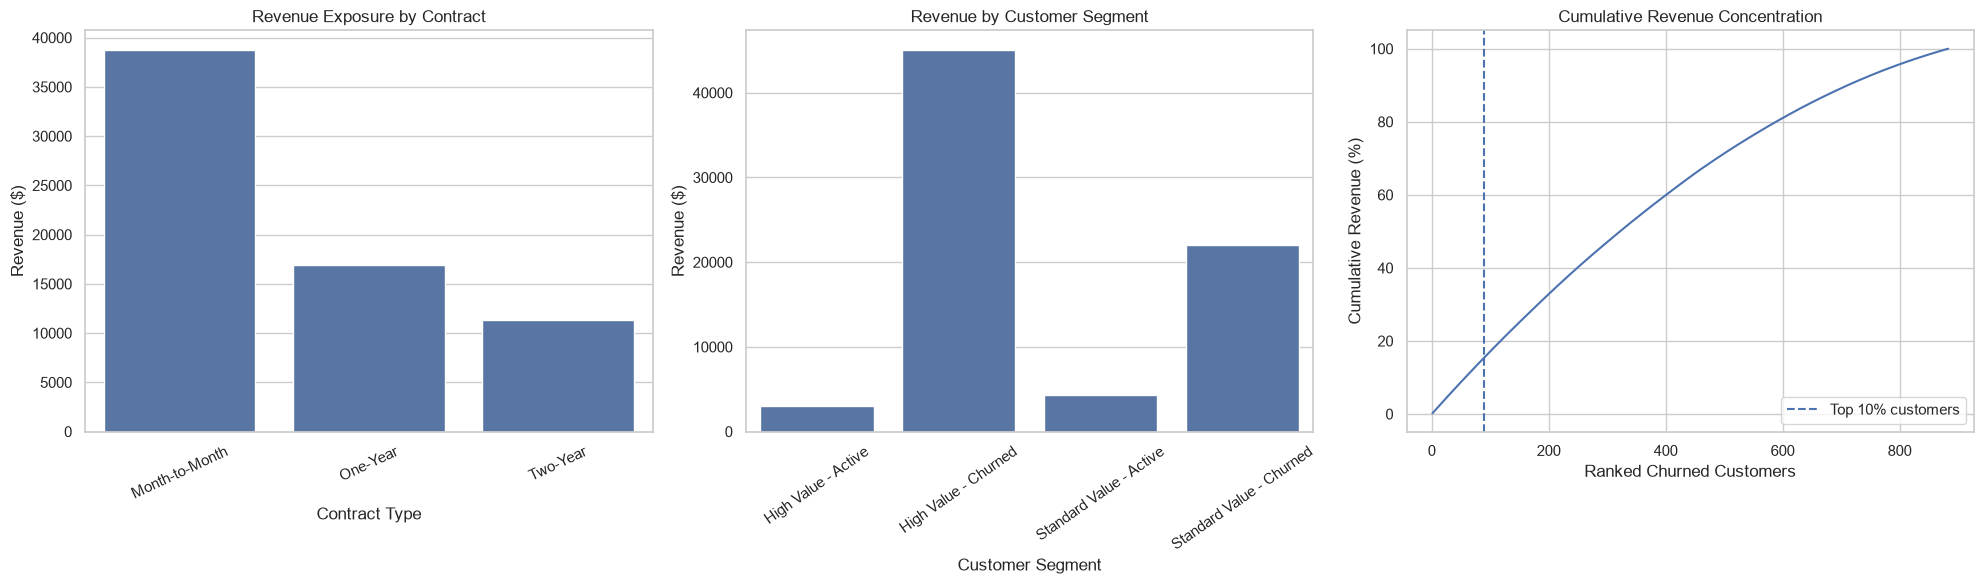

In [119]:

# STEP 7: REVENUE AT RISK VISUALIZATION

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Revenue exposure by contract type
sns.barplot(
    data=contract_analysis.reset_index(),
    x="ContractType",
    y="Revenue_At_Risk",
    ax=axes[0]
)

axes[0].set_title("Revenue Exposure by Contract")
axes[0].set_xlabel("Contract Type")
axes[0].set_ylabel("Revenue ($)")
axes[0].tick_params(axis="x", rotation=25)

# 2. Revenue by customer segment
sns.barplot(
    data=segment_analysis.reset_index(),
    x="CustomerSegment",
    y="Total_Monthly_Charges",
    ax=axes[1]
)

axes[1].set_title("Revenue by Customer Segment")
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Revenue ($)")
axes[1].tick_params(axis="x", rotation=35)

# 3. Cumulative revenue concentration
axes[2].plot(
    range(1, len(churned_df) + 1),
    churned_df["Cumulative_Revenue_Pct"]
)

axes[2].axvline(
    top_10_count,
    linestyle="--",
    label="Top 10% customers"
)

axes[2].set_title("Cumulative Revenue Concentration")
axes[2].set_xlabel("Ranked Churned Customers")
axes[2].set_ylabel("Cumulative Revenue (%)")
axes[2].legend()

plt.tight_layout()
plt.show()


Revenue Exposure by Contract: Month-to-Month contracts contribute the highest historical revenue exposure.



Revenue by Customer Segment: High Value – Churned customers account for the largest revenue contribution.



Cumulative Revenue Concentration: The top 10% of churned customers contribute 15.34% of churn-associated monthly charges.

# Revenue at Risk and Customer Value Analysis

## Executive Summary

This analysis examines the financial exposure associated with customer churn in a telecom customer dataset containing 1,000 customers.

The objective is to move beyond customer churn counts and understand the associated monthly revenue exposure, identify financially important customer segments, and provide insights that can support retention strategy decisions.

## Key Business Findings

### 1. Revenue Exposure
- Total monthly charges across the dataset: $74,391.29.
- Churn-associated revenue exposure: 90.16% of total monthly charges.

### 2. Contract Analysis
- Month-to-Month customers account for $38,789.60 in churn-associated monthly charges.
- This represents 57.83% of total churn-associated revenue.
- The observed churn rate for Month-to-Month customers is 100%.

### 3. Customer Value Analysis
- High-value customers account for $45,097.65 in churn-associated monthly charges.
- This represents 67.25% of total churn-associated revenue.
- High-value customers have an observed churn rate of 93.15%.

### 4. Revenue Concentration
- The top 10% of churned customers represent 89 customers.
- These customers account for $10,289.48 in monthly charges.
- They contribute 15.34% of churn-associated revenue.

## Business Recommendations

1. Investigate the high churn observed among Month-to-Month contract customers.
2. Prioritize analysis of high-value customer attrition because this segment contributes the largest share of revenue exposure.
3. Investigate pricing, service quality and customer tenure as possible factors associated with churn.
4. Evaluate targeted retention offers through controlled campaigns before scaling them.
5. Monitor customer value and churn trends regularly to support retention planning.

## Important Limitations

- The dataset contains only 1,000 customer records.
- The overall churn rate is unusually high at 88.3%.
- The analysis uses monthly charges associated with customers labelled as churned; it does not establish actual recoverable revenue or future revenue loss.
- Retention campaign costs, intervention success rates and customer profitability are unavailable.
- Findings are descriptive and do not establish causation.

## Conclusion

The analysis identifies Month-to-Month contracts and high-value customers as important areas for further investigation.

By combining customer churn information with financial analysis, the business can better understand where revenue exposure is concentrated and make more informed decisions about retention strategy.